# RUVSeq: Python tutorial

RUVg, RUVr and RUVs matrix methods plus replicate-index construction. No EDASeq objects, automatic control selection or downstream DE.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parent
sys.path.insert(0,str(ROOT))
from pyruvseq import *


## Run the public functions
The example uses checked-in fixtures. Labels and matrix orientations are explicit. See function docstrings before substituting your own data.

{'RUVg': (16, 2), 'RUVr': (16, 2), 'RUVs': (16, 2)}


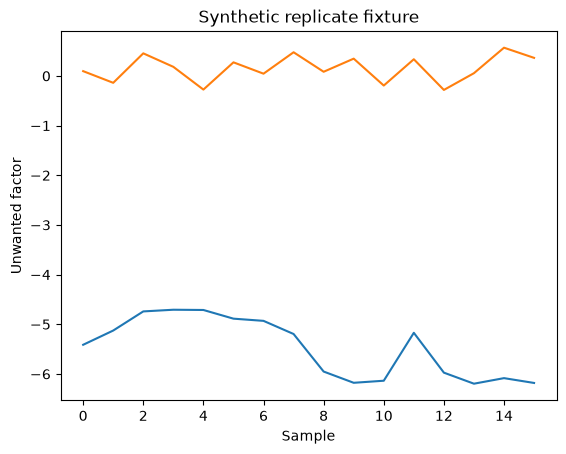

In [2]:
x=np.loadtxt(ROOT/'data/input.csv',delimiter=',')
residuals=np.loadtxt(ROOT/'data/residuals.csv',delimiter=',')
groups=make_groups(np.repeat(list('abcd'),4))
g=ruvg(x,range(12),2,round_counts=False)
r=ruvr(x,range(12),2,residuals,round_counts=False)
s=ruvs(x,range(12),2,groups,round_counts=False)
print({name: value['W'].shape for name,value in [('RUVg',g),('RUVr',r),('RUVs',s)]})
plt.plot(s['W']);plt.xlabel('Sample');plt.ylabel('Unwanted factor');plt.title('Synthetic replicate fixture');plt.show()


## Parameters and pitfalls
R uses one-based indices; Python integer indices are zero-based. Preserve biological-sample identities. Do not interpret descriptive factors or deconvolution fractions as differential-test p-values.

In [3]:
import inspect
import importlib
api=importlib.import_module('pyruvseq')
rows=[]
for name in api.__all__:
    function=getattr(api,name)
    if not inspect.isfunction(function): continue
    for parameter in inspect.signature(function).parameters.values():
        rows.append({'Python function':name,'parameter':parameter.name,'default':str(parameter.default),
                     'contract':inspect.getdoc(function)})
display(pd.DataFrame(rows))


,Python function,parameter,default,contract
0,ruvg,expression,<class 'inspect._empty'>,Estimate RUVg factors from a genes-by-samples ...
1,ruvg,controls,<class 'inspect._empty'>,Estimate RUVg factors from a genes-by-samples ...
2,ruvg,k,1,Estimate RUVg factors from a genes-by-samples ...
3,ruvg,drop,0,Estimate RUVg factors from a genes-by-samples ...
4,ruvg,center,True,Estimate RUVg factors from a genes-by-samples ...
5,ruvg,round_counts,True,Estimate RUVg factors from a genes-by-samples ...
6,ruvg,epsilon,1.0,Estimate RUVg factors from a genes-by-samples ...
7,ruvg,tolerance,1e-08,Estimate RUVg factors from a genes-by-samples ...
8,ruvg,is_log,False,Estimate RUVg factors from a genes-by-samples ...
9,ruvr,x,<class 'inspect._empty'>,Estimate unwanted factors from caller-supplied...
